# Real Estate Housing Price Prediction
## OLS vs Ridge (L2) vs Lasso (L1) on California Housing

**Datheon Machine Learning & Data Science Internship — Task 2**

### Objective

Predict the median house value of California census block groups and compare three
linear regression models:

1. **Ordinary Least Squares (OLS)** — unregularized baseline.
2. **Ridge regression (L2)** — shrinks correlated coefficients.
3. **Lasso regression (L1)** — shrinks and can zero out coefficients.

The workflow validates the data, explores distributions and correlations, engineers
safe ratio features, splits the rows before any learned preprocessing, tunes
regularization with five-fold cross-validation, and evaluates once on an untouched
test set. **All reported numbers in this notebook are produced by executing the
cells, not typed in manually.**

## 1. Dataset description

The dataset is loaded with
`sklearn.datasets.fetch_california_housing(as_frame=True)`. It contains **20,640
census block groups** and eight numeric predictors:

| Column | Meaning |
| --- | --- |
| `MedInc` | Median household income (tens of thousands of USD) |
| `HouseAge` | Median house age in years |
| `AveRooms` | Average rooms per household |
| `AveBedrms` | Average bedrooms per household |
| `Population` | Block-group population |
| `AveOccup` | Average household occupancy |
| `Latitude` | Latitude |
| `Longitude` | Longitude |

The target is **`MedHouseVal`**, measured in units of **$100,000**. For example, a
value of `2.5` means approximately **$250,000**. The original dataset has no missing
values and no categorical columns; the pipeline still supports imputation and
one-hot encoding, and those paths are covered by tests. The upper target value is
capped near `5.00001` (about $500,001), which is an important limitation.

## 2. Imports and configuration

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    TARGET_UNIT,
    load_california_housing,
    summarize_dataset,
    validate_dataset,
)
from src.features import (
    ENGINEERED_FEATURE_COLUMNS,
    ENGINEERED_FEATURE_DESCRIPTIONS,
    add_engineered_features,
    variance_inflation_factors,
)
from src.preprocessing import build_preprocessor, prepare_datasets
from src.train import (
    fit_ols,
    predict_house_value,
    predict_house_value_dollars,
    save_models,
    tune_regularized_model,
)
from src.evaluate import evaluate_results, write_evaluation_reports
from src.visualize import (
    generate_diagnostic_figures,
    generate_eda_figures,
    plot_vif_analysis,
    save_figure,
    set_plot_style,
)

RANDOM_STATE = 42
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
MODEL_DIR = PROJECT_ROOT / "models"
for directory in (FIGURE_DIR, REPORT_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
set_plot_style()


def show_figure(path, width=950):
    """Display a saved PNG inside the notebook."""
    display(Image(filename=str(path), width=width))


print(f"Project root: {PROJECT_ROOT}")
print(f"pandas {pd.__version__} | NumPy {np.__version__}")
print(f"Target unit: {TARGET_UNIT}")

Project root: D:\Datheon Project\Real Estate Housing Predication2 Task2\task_2_house_price_prediction
pandas 3.1.0 | NumPy 2.5.4
Target unit: $100,000


## 3. Data loading and validation

In [2]:
frame = load_california_housing()
validation = validate_dataset(frame)
summary = summarize_dataset(frame)

print(f"Shape: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
print(f"Missing cells: {validation['missing_values']['total_missing_cells']}")
print(f"Duplicate rows: {validation['duplicate_rows']}")
print(f"Target: {TARGET_COLUMN} (unit: {TARGET_UNIT})")
print(f"Validation status: {'PASSED' if validation['is_valid'] else 'FAILED'}")

display(frame.head())
display(
    pd.DataFrame(
        {
            "dtype": frame.dtypes.astype(str),
            "missing": frame.isna().sum(),
            "unique": frame.nunique(),
        }
    )
)
display(frame.describe().T)

Shape: 20,640 rows x 9 columns
Missing cells: 0
Duplicate rows: 0
Target: MedHouseVal (unit: $100,000)
Validation status: PASSED


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,dtype,missing,unique
MedInc,float64,0,12928
HouseAge,float64,0,52
AveRooms,float64,0,19392
AveBedrms,float64,0,14233
Population,float64,0,3888
AveOccup,float64,0,18841
Latitude,float64,0,862
Longitude,float64,0,844
MedHouseVal,float64,0,3842


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


### Target distribution summary

The table below translates the target moments into dollars for readability. The
mean is about $207k and the median about $180k, so the distribution is right-skewed.

In [3]:
target_table = pd.DataFrame(
    {
        "value_100k": [
            summary["target"]["mean"],
            summary["target"]["median"],
            summary["target"]["std"],
            summary["target"]["min"],
            summary["target"]["max"],
        ],
        "approx_usd": [
            summary["target"]["mean"] * 100_000,
            summary["target"]["median"] * 100_000,
            summary["target"]["std"] * 100_000,
            summary["target"]["min"] * 100_000,
            summary["target"]["max"] * 100_000,
        ],
    },
    index=["mean", "median", "std", "min", "max"],
)
display(target_table.round(2))
print(
    f"Rows at the upper cap: {summary['target']['capped_count']:,} "
    f"({summary['target']['capped_fraction']:.2%})"
)

assert TARGET_COLUMN not in FEATURE_COLUMNS
assert validation["is_valid"]
assert summary["target"]["capped_count"] > 0

,value_100k,approx_usd
mean,2.07,206855.82
median,1.80,179700.00
std,1.15,115395.62
min,0.15,14999.00
max,5.00,500001.00


Rows at the upper cap: 965 (4.68%)


## 4. Exploratory data analysis

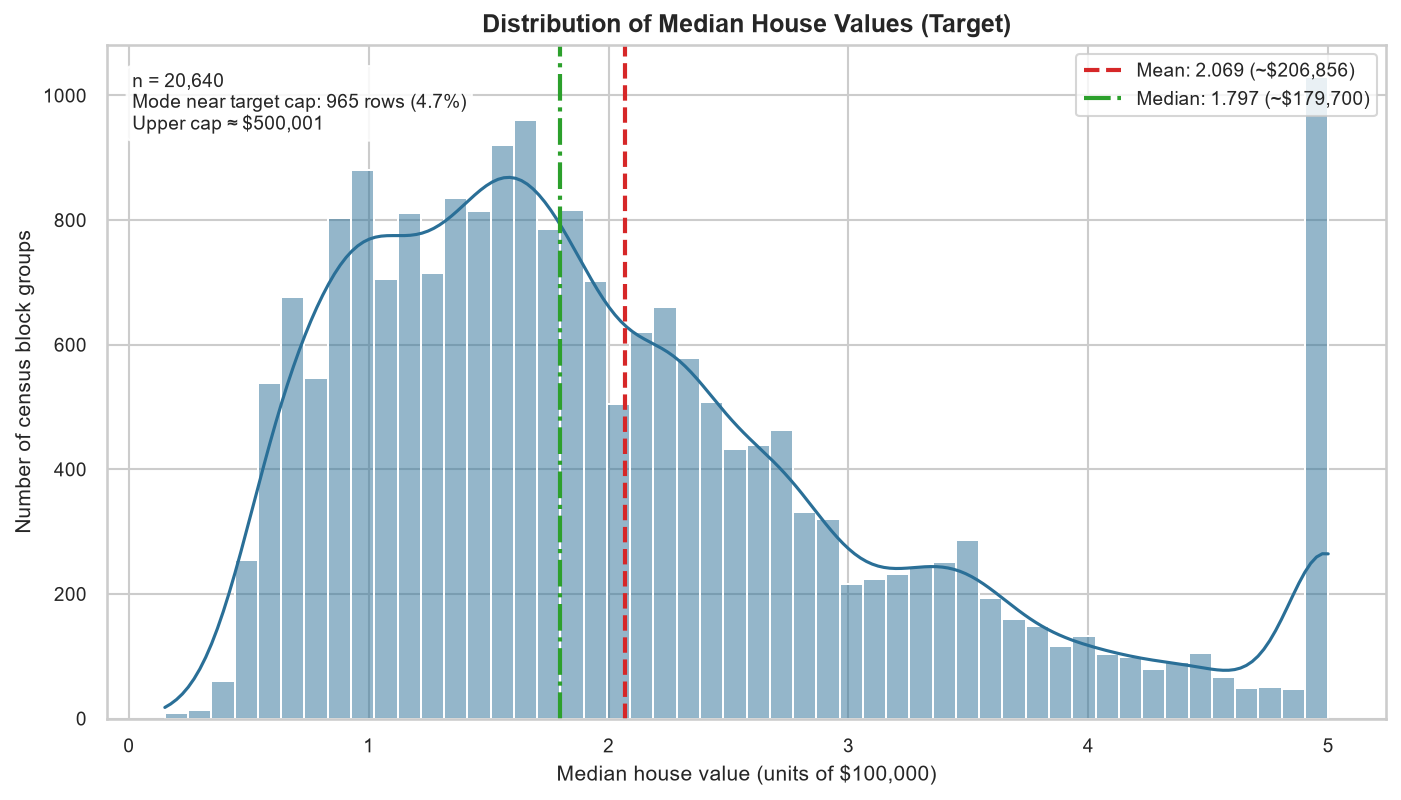

In [4]:
eda_paths = generate_eda_figures(frame, FIGURE_DIR)
show_figure(eda_paths["target_distribution"])

The target is right-skewed and capped at about **$500,001**. The large spike at the
cap (965 rows, 4.68%) means the model cannot distinguish prices above that ceiling;
this will show up as under-prediction for expensive block groups later.

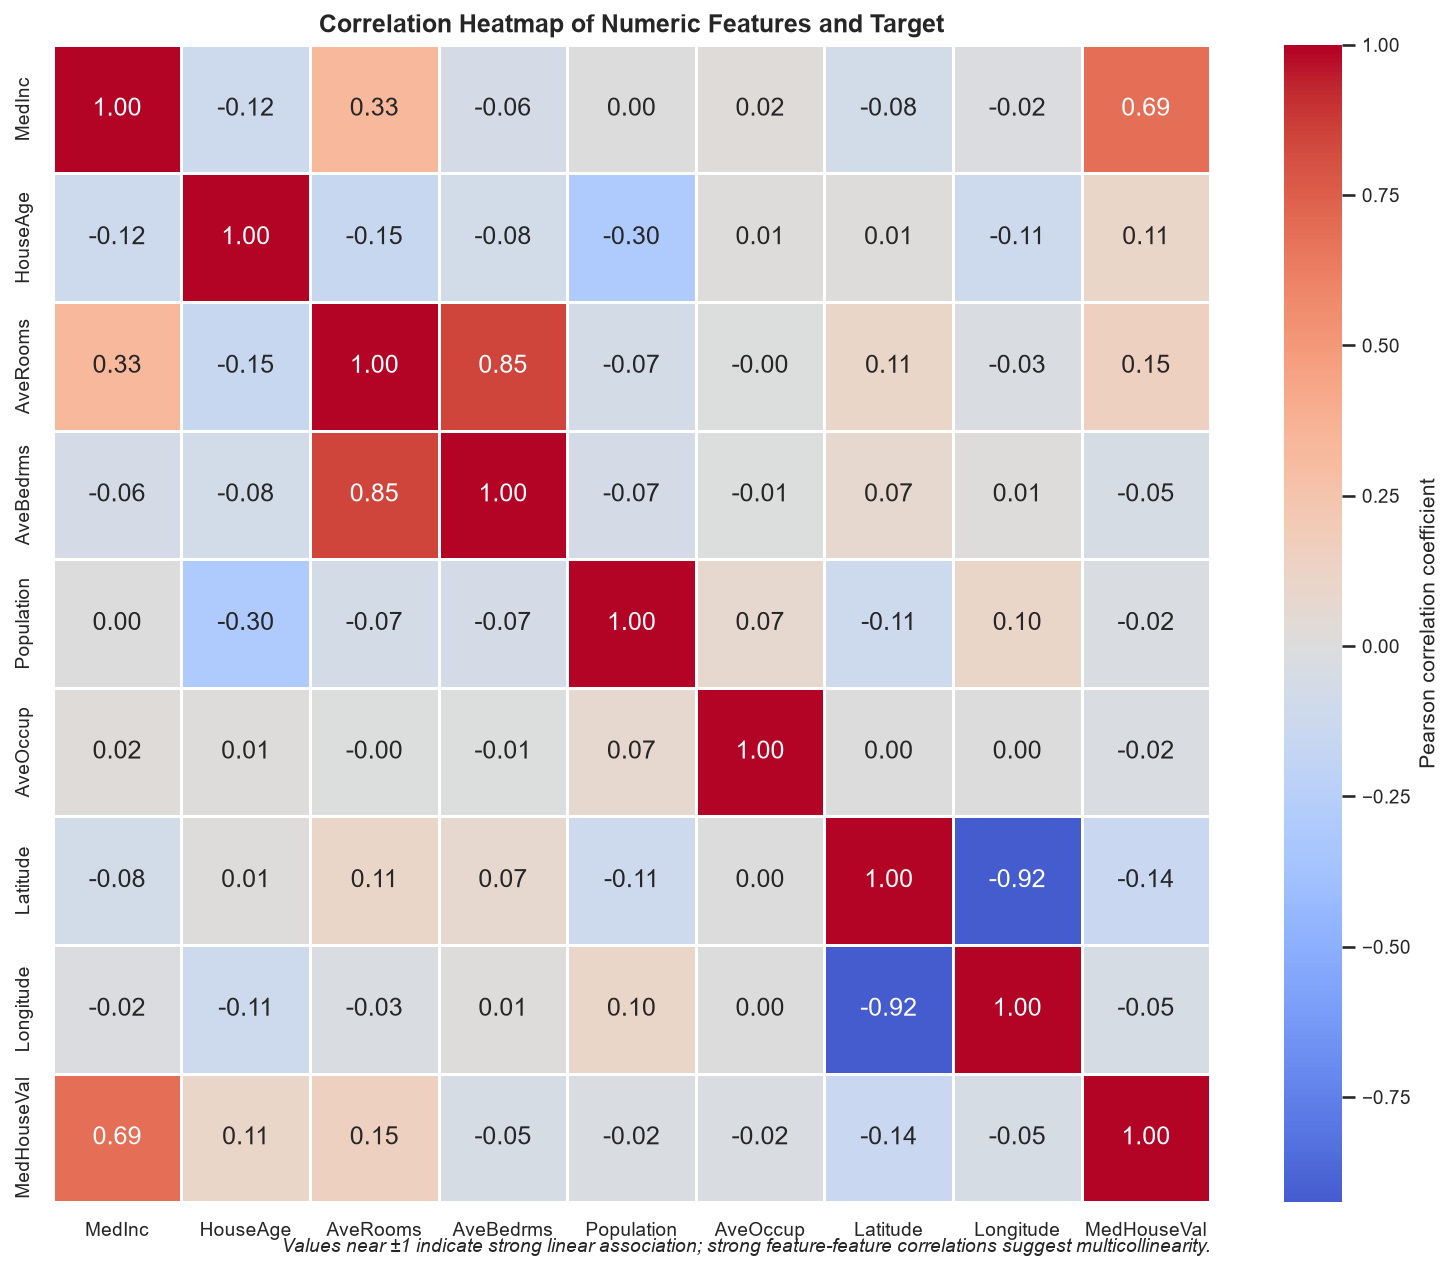

,Pearson r with MedHouseVal
MedInc,0.688
AveRooms,0.152
HouseAge,0.106
AveOccup,-0.024
Population,-0.025
Longitude,-0.046
AveBedrms,-0.047
Latitude,-0.144


absolute Pearson r
Latitude Longitude                0.925
AveRooms AveBedrms                0.848
MedInc   AveRooms                 0.327
HouseAge Population               0.296
         AveRooms                 0.153
MedInc   HouseAge                 0.119

In [5]:
show_figure(eda_paths["correlation_heatmap"])

target_correlations = (
    frame.corr(numeric_only=True)[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(ascending=False)
)
display(target_correlations.to_frame("Pearson r with MedHouseVal").round(3))

feature_corr = frame.drop(columns=TARGET_COLUMN).corr().abs()
upper_mask = np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
top_pairs = (
    feature_corr.where(upper_mask)
    .stack()
    .sort_values(ascending=False)
    .head(6)
    .to_frame("absolute Pearson r")
)
display(top_pairs.round(3))

**Correlation findings.**

- `MedInc` is by far the strongest single linear correlate of the target
  (`r ≈ 0.69`), followed by `AveRooms` (`r ≈ 0.15`) and `HouseAge` (`r ≈ 0.11`).
- `Latitude` and `Longitude` have weak marginal correlations but are strongly
  related to each other (`|r| ≈ 0.925`), creating geographic multicollinearity.
- `AveRooms` and `AveBedrms` are also strongly related (`r ≈ 0.848`).
- Correlation measures linear association only; the geographic map below shows
  that location has a strong non-linear relationship with price.

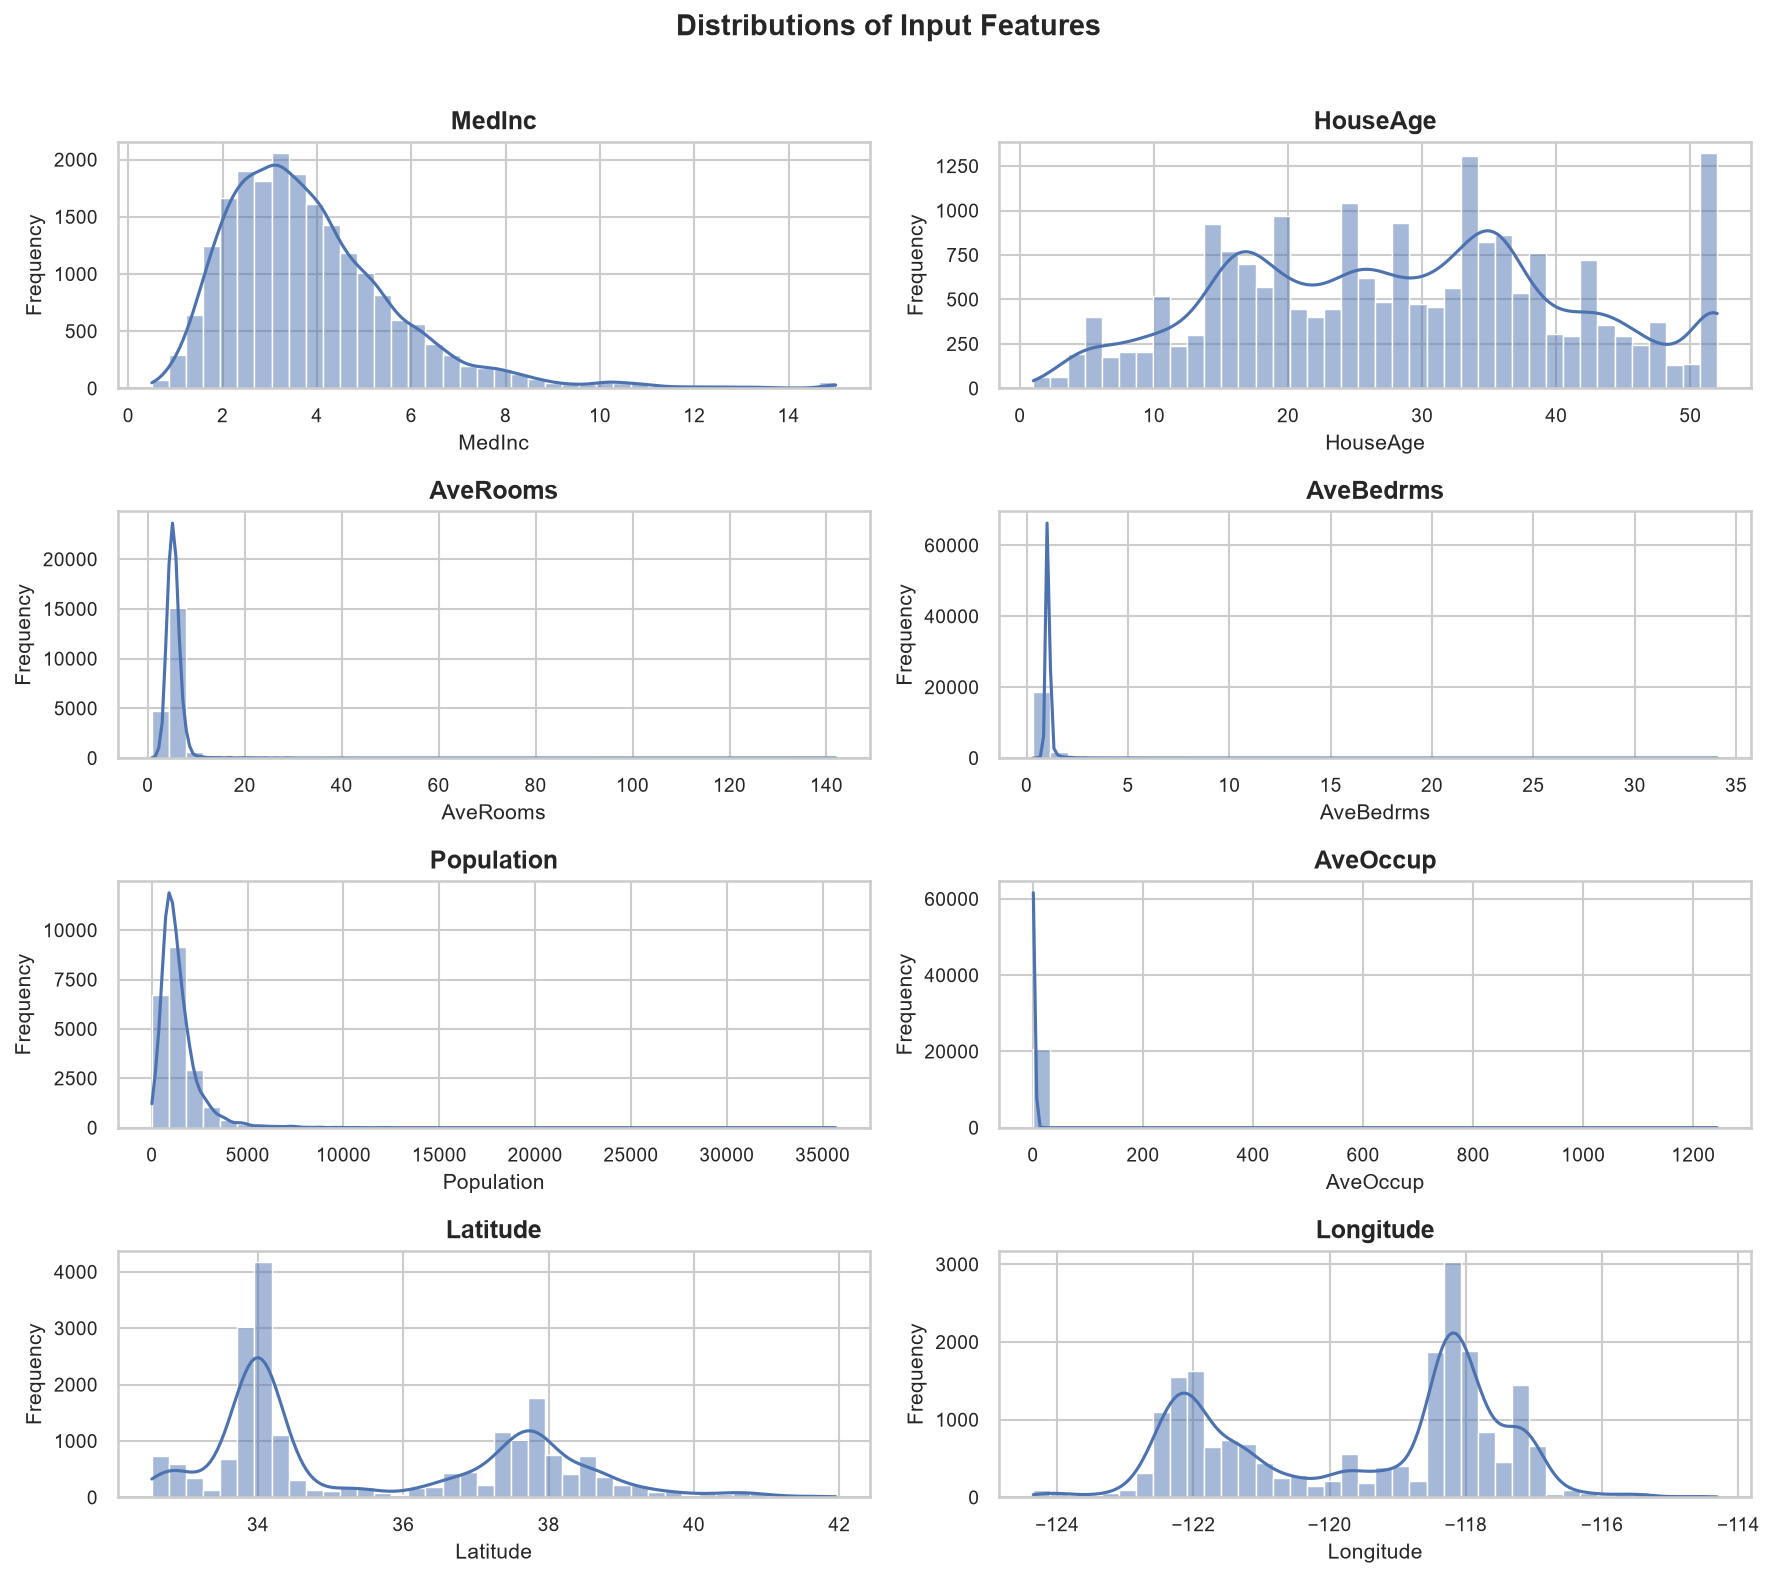

In [6]:
show_figure(eda_paths["feature_distributions"])

Most features are skewed. `Population` and `AveOccup` have long right tails,
`AveRooms` has a few very large block-group averages, and `MedInc` is
right-skewed. Standard scaling does not remove skew; the engineered
`LogPopulation` feature partially addresses the population tail.

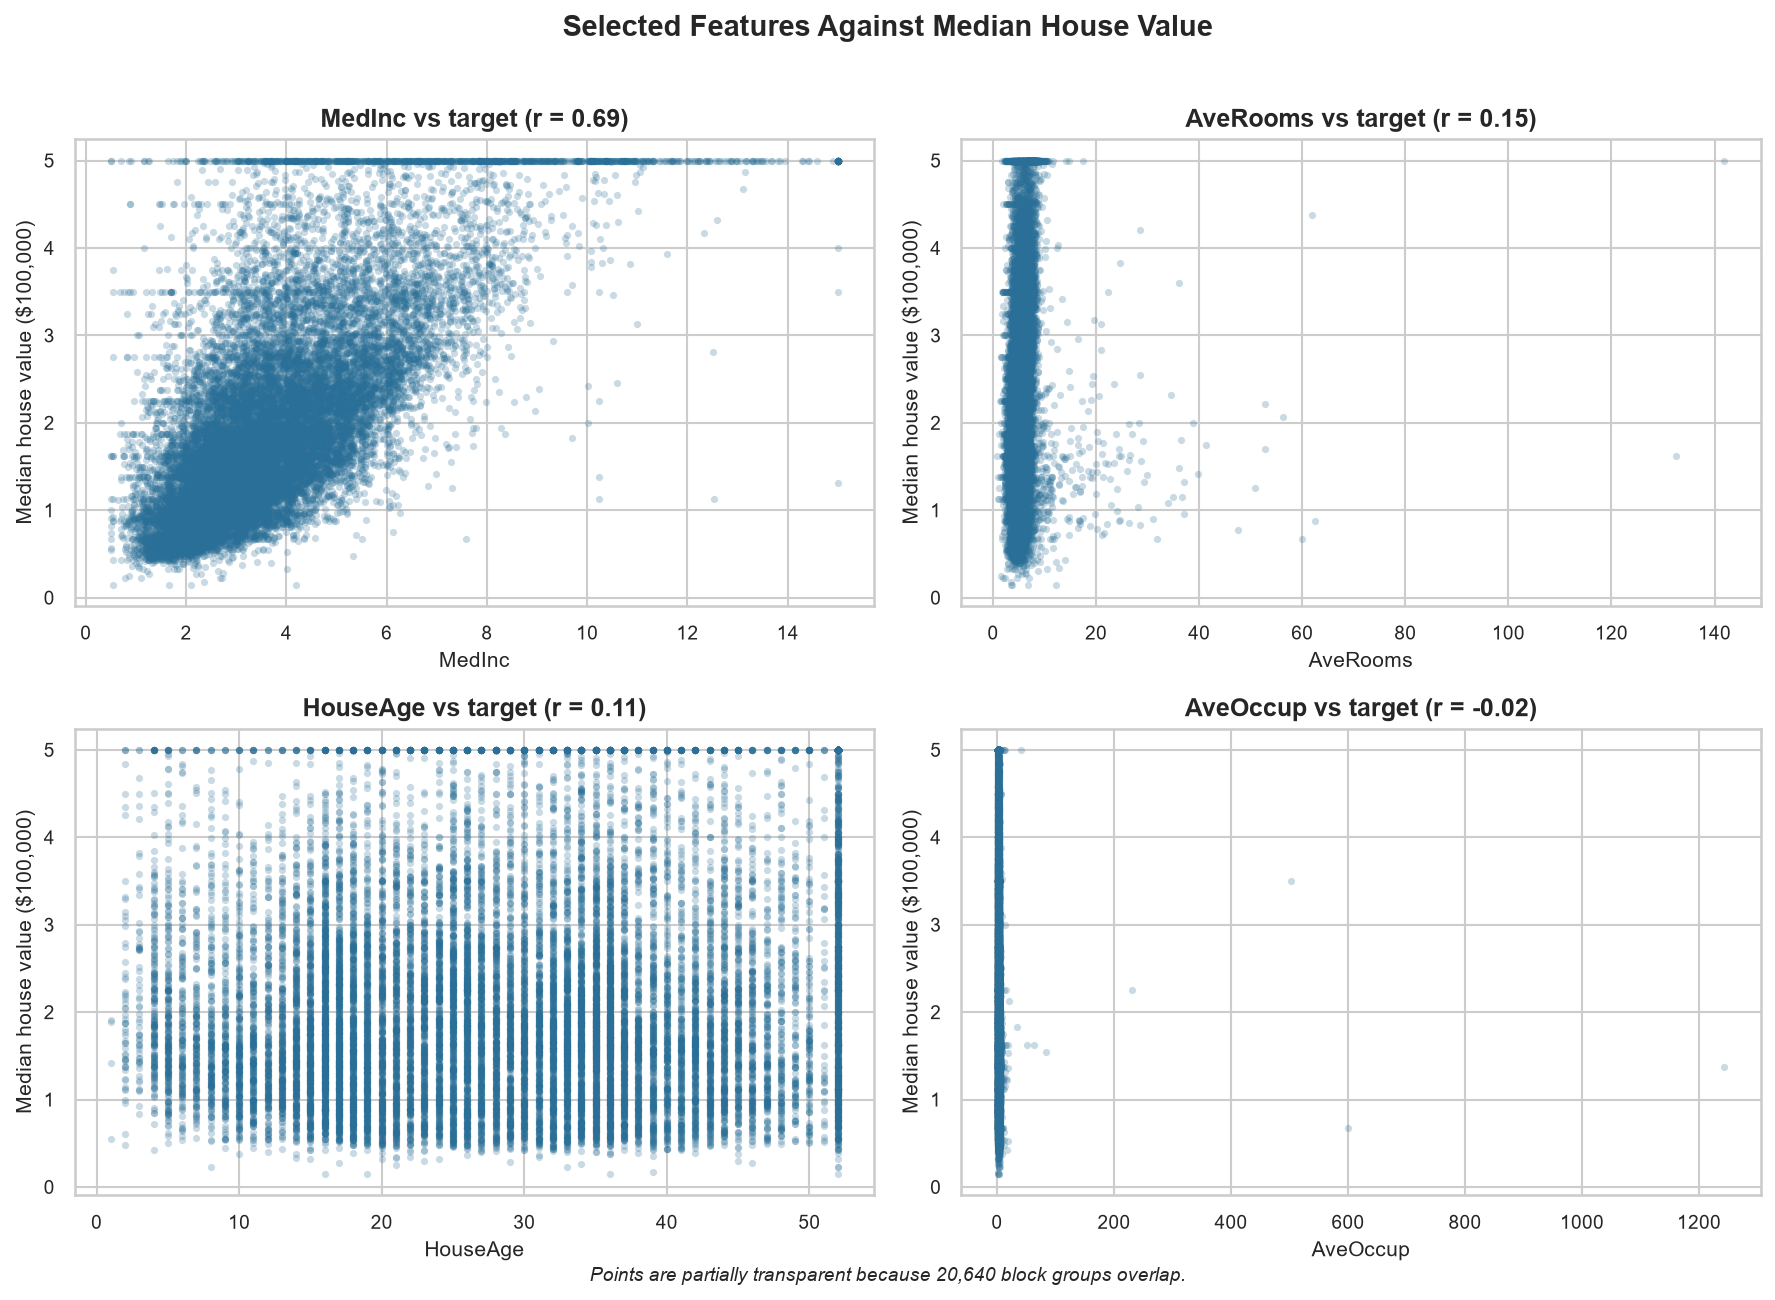

In [7]:
show_figure(eda_paths["feature_target_scatter"])

The scatterplots show a positive but noisy income relationship and a much weaker
relationship for room count, age, and occupancy. The target cap appears as a
horizontal band at the top. A single global linear slope cannot capture all of
these patterns, which motivates the residual analysis later.

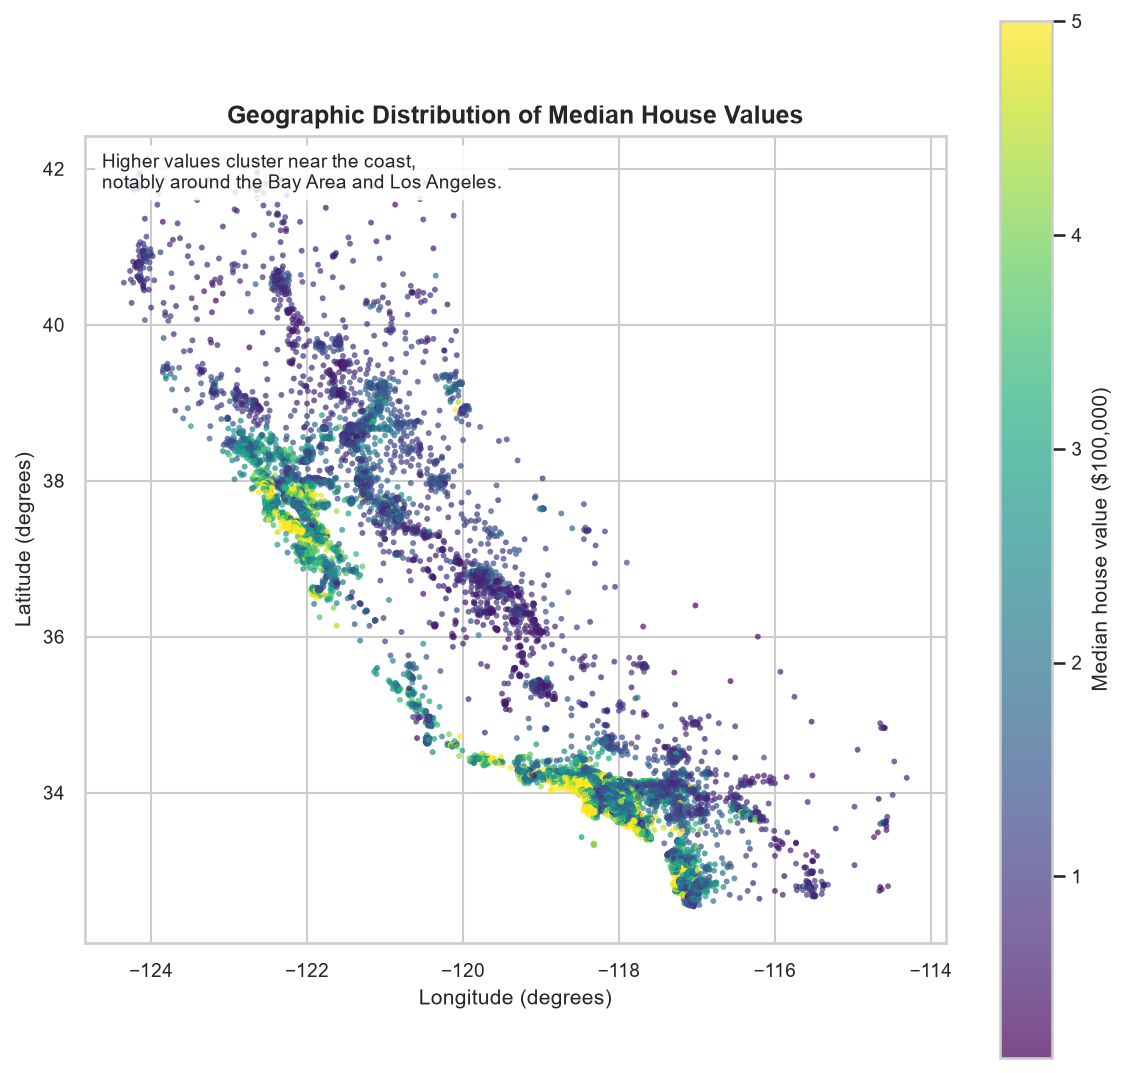

In [8]:
show_figure(eda_paths["geographic_target"], width=650)

Location matters: high-value block groups cluster near the coast, especially around
the San Francisco Bay Area and Los Angeles. Raw latitude and longitude cannot fully
express this spatial pattern, so a linear model is expected to leave spatial
structure in its residuals.

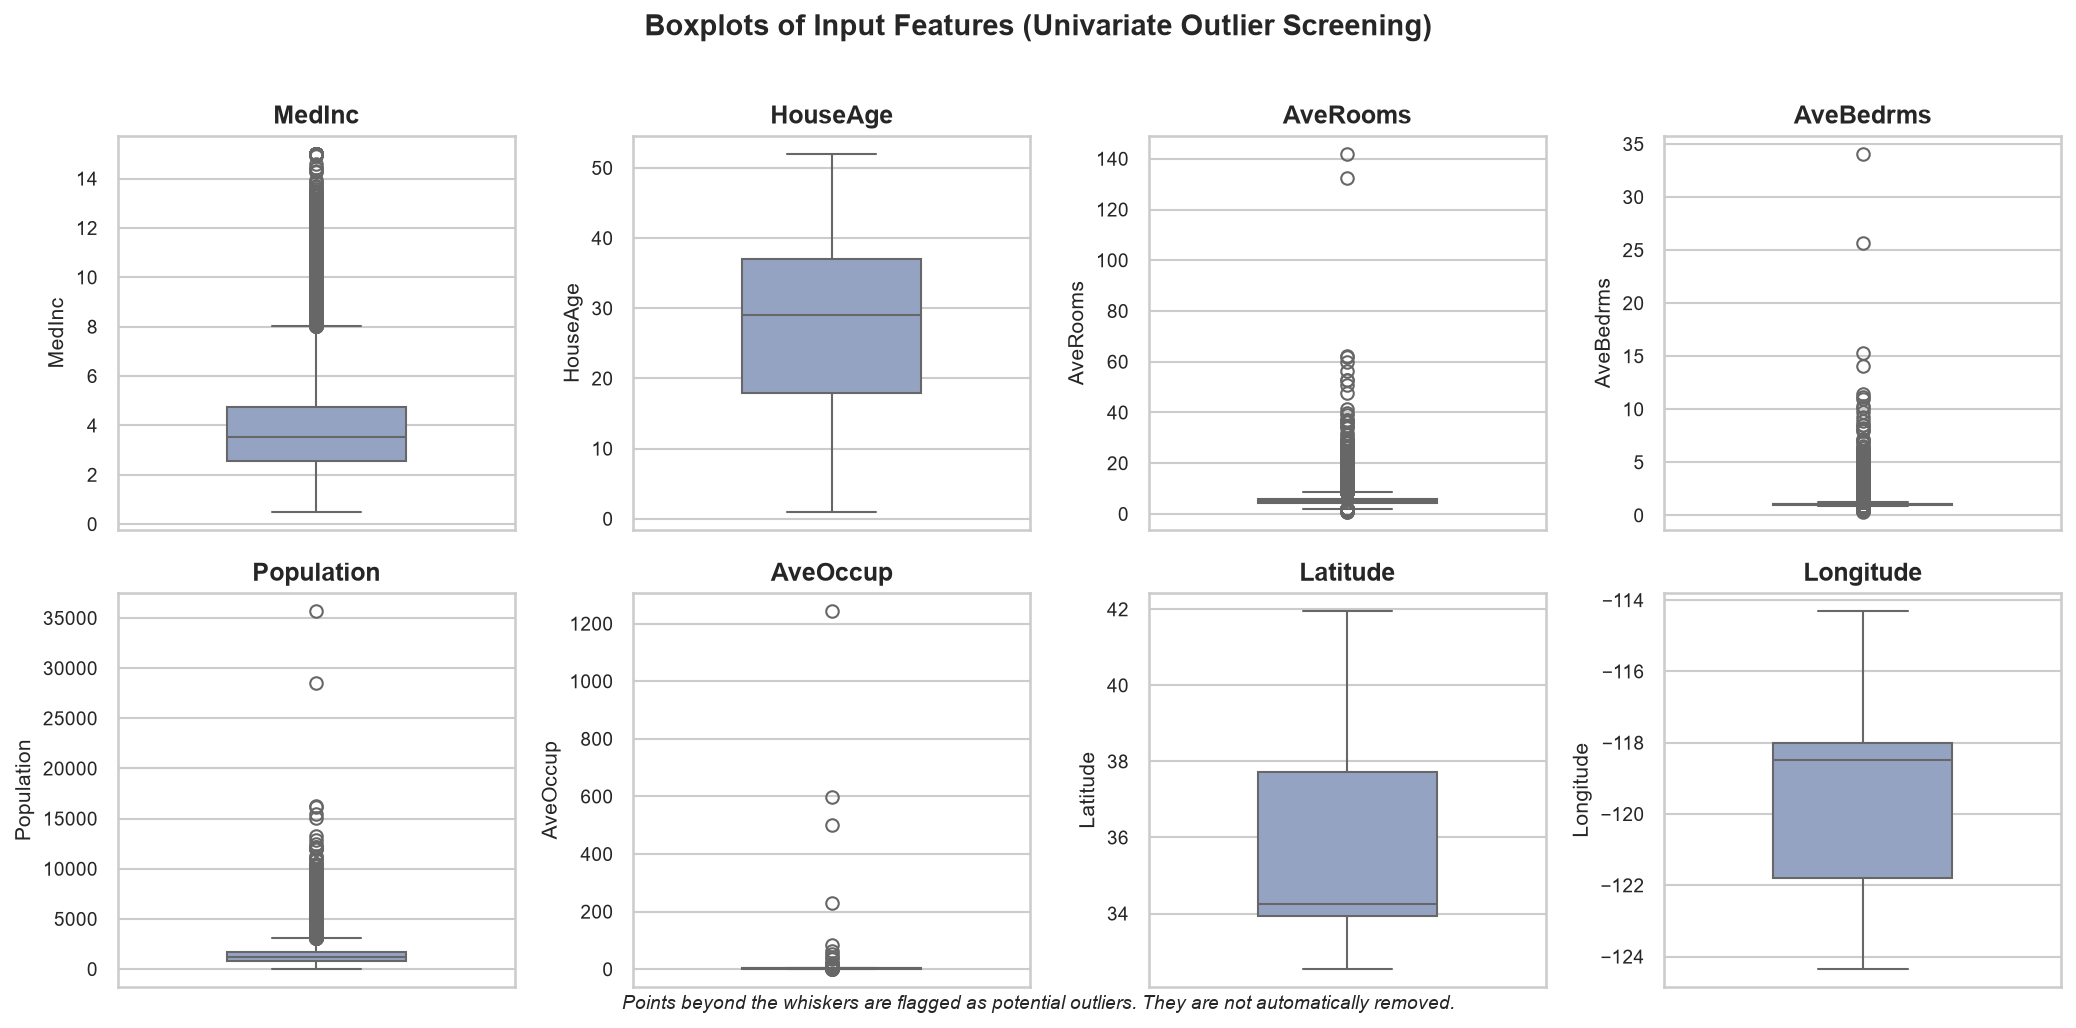

In [9]:
show_figure(eda_paths["feature_boxplots"])

The boxplots flag many univariate outliers, especially in `AveRooms`, `AveBedrms`,
`Population`, and `AveOccup`. These are largely legitimate aggregated census
measurements, so they are **not automatically removed**. Scaling limits their
numerical leverage, and regularization helps stabilize coefficients.

## 5. Missing-value analysis

In [10]:
missing_table = pd.DataFrame(
    {
        "missing_count": frame.isna().sum(),
        "missing_fraction": frame.isna().mean(),
    }
)
display(missing_table)
print(f"Total missing cells: {int(frame.isna().sum().sum())}")
print(f"Duplicate rows: {int(frame.duplicated().sum())}")

# Demonstrate the missing-value path without altering the real dataset.
imputation_demo = pd.DataFrame(
    {
        "numeric_feature": [1.0, np.nan, 3.0, 3.0],
        "categorical_feature": ["a", None, "a", "b"],
    }
)
demo_preprocessor = build_preprocessor(["numeric_feature"], ["categorical_feature"])
demo_transformed = demo_preprocessor.fit_transform(imputation_demo)
demo_numeric_imputer = demo_preprocessor.named_transformers_["numeric"].named_steps[
    "imputer"
]
demo_categorical_imputer = demo_preprocessor.named_transformers_[
    "categorical"
].named_steps["imputer"]

print(
    "Demo numeric median imputation value: "
    f"{demo_numeric_imputer.statistics_[0]:.1f}"
)
print(
    "Demo categorical most-frequent value: "
    f"{demo_categorical_imputer.statistics_[0]}"
)
print(f"Demo transformed shape: {demo_transformed.shape}")
display(pd.DataFrame(demo_transformed, columns=demo_preprocessor.get_feature_names_out()))

,missing_count,missing_fraction
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


Total missing cells: 0
Duplicate rows: 0
Demo numeric median imputation value: 3.0
Demo categorical most-frequent value: a
Demo transformed shape: (4, 3)


,numeric_feature,categorical_feature_a,categorical_feature_b
0,-1.732051,1.0,0.0
1,0.577350,1.0,0.0
2,0.577350,1.0,0.0
3,0.577350,0.0,1.0


The real California Housing data has **no missing values**, so no rows are dropped
or invented. The median numeric imputer and most-frequent categorical imputer are
still part of the pipeline because they are required for robustness and are tested
on synthetic data. All imputation statistics and scaling parameters are fitted on
training data only.

## 6. Feature engineering

In [11]:
engineered_frame = add_engineered_features(frame)
preview_columns = list(FEATURE_COLUMNS) + list(ENGINEERED_FEATURE_COLUMNS)
display(engineered_frame[preview_columns].head())
display(engineered_frame[list(ENGINEERED_FEATURE_COLUMNS)].describe().T)

for name, description in ENGINEERED_FEATURE_DESCRIPTIONS.items():
    print(f"- {name}: {description}")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomRatio,IncomePerPerson,LogPopulation
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,2.732919,0.146591,3.257687,5.777652
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,2.956685,0.155797,3.934608,7.784057
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,2.957661,0.129516,2.589838,6.208590
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,2.283154,0.184458,2.214765,6.326149
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,2.879646,0.172096,1.763125,6.338594


,count,mean,std,min,25%,50%,75%,max
RoomsPerPerson,20640.0,1.976970,1.146020,0.002547,1.522382,1.937936,2.296090,55.222222
BedroomRatio,20640.0,0.213075,0.058023,0.100000,0.175426,0.203181,0.239834,1.000000
IncomePerPerson,20640.0,1.408324,0.755017,0.008225,0.869633,1.295461,1.775809,7.549836
LogPopulation,20640.0,7.025503,0.736238,1.386294,6.669498,7.062192,7.453562,10.482430


- RoomsPerPerson: AveRooms / AveOccup. Approximates living space per occupant and separates crowded households from spacious ones, which the raw averages mix together.
- BedroomRatio: AveBedrms / AveRooms. Captures the bedroom share of a home; a high ratio suggests smaller units or studios, while a low ratio suggests larger homes.
- IncomePerPerson: MedInc / AveOccup. Scales neighbourhood income by household size and gives a rough proxy for individual economic capacity.
- LogPopulation: log1p(Population). Compresses the long right tail of block-group population, reducing the leverage of very large census areas.


| Feature | Formula | Why it may help |
| --- | --- | --- |
| `RoomsPerPerson` | `AveRooms / AveOccup` | Separates spacious homes from crowded ones. |
| `BedroomRatio` | `AveBedrms / AveRooms` | Approximates unit size / layout. |
| `IncomePerPerson` | `MedInc / AveOccup` | Scales income by household size. |
| `LogPopulation` | `log1p(Population)` | Compresses the population tail. |

Division is implemented with `safe_divide`, which returns `NaN` for zero, near-zero,
or missing denominators. The imputer handles those values in the pipeline. The
target is never used, and the same stateless function is applied separately to the
training and test frames.

## 7. Train-test split

In [12]:
prepared = prepare_datasets(frame, random_state=RANDOM_STATE)

split_table = pd.DataFrame(
    {
        "rows": [len(prepared.X_train), len(prepared.X_test)],
        "target_mean_100k": [
            prepared.y_train.mean(),
            prepared.y_test.mean(),
        ],
        "target_median_100k": [
            prepared.y_train.median(),
            prepared.y_test.median(),
        ],
    },
    index=["train", "test"],
)
display(split_table.round(4))
print(f"Training features: {prepared.X_train.shape}")
print(f"Test features: {prepared.X_test.shape}")
print(f"Numeric columns: {list(prepared.numeric_features)}")
print(f"Categorical columns: {list(prepared.categorical_features)}")
print(f"Engineered columns present: {[c for c in prepared.X_train.columns if c in ENGINEERED_FEATURE_COLUMNS]}")

assert TARGET_COLUMN not in prepared.X_train.columns
assert set(prepared.X_train.index).isdisjoint(set(prepared.X_test.index))
assert len(prepared.X_test) / (len(prepared.X_train) + len(prepared.X_test)) == 0.2

,rows,target_mean_100k,target_median_100k
train,16512,2.0719,1.7985
test,4128,2.0550,1.7865


Training features: (16512, 12)
Test features: (4128, 12)
Numeric columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'RoomsPerPerson', 'BedroomRatio', 'IncomePerPerson', 'LogPopulation']
Categorical columns: []
Engineered columns present: ['RoomsPerPerson', 'BedroomRatio', 'IncomePerPerson', 'LogPopulation']


The 80/20 split is created **before** scaling, imputation, or any model fitting.
The test target is stored separately and is not passed to a model or grid search in
the following sections.

## 8. Preprocessing pipeline

In [13]:
preprocessor = build_preprocessor(
    prepared.numeric_features, prepared.categorical_features
)

# Fit only on training rows, then apply the learned transformation to both splits.
X_train_processed = preprocessor.fit_transform(prepared.X_train)
X_test_processed = preprocessor.transform(prepared.X_test)
processed_feature_names = [str(name) for name in preprocessor.get_feature_names_out()]

print(f"Raw training shape: {prepared.X_train.shape}")
print(f"Processed training shape: {X_train_processed.shape}")
print(f"Processed test shape: {X_test_processed.shape}")
print(f"Maximum absolute training-column mean after scaling: {np.abs(X_train_processed.mean(axis=0)).max():.3e}")
print(f"Any non-finite values: {not np.isfinite(X_train_processed).all() or not np.isfinite(X_test_processed).all()}")
print(f"First transformed features: {processed_feature_names[:6]}")

display(
    pd.DataFrame(
        X_train_processed[:3], columns=processed_feature_names
    ).iloc[:, :8]
)

Raw training shape: (16512, 12)
Processed training shape: (16512, 12)
Processed test shape: (4128, 12)
Maximum absolute training-column mean after scaling: 3.386e-15
Any non-finite values: False
First transformed features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,-0.326196,0.348490,-0.174916,-0.208365,0.768276,0.051376,-1.372811,1.272587
1,-0.035843,1.618118,-0.402835,-0.128530,-0.098901,-0.117362,-0.876696,0.709162
2,0.144701,-1.952710,0.088216,-0.257538,-0.449818,-0.032280,-0.460146,-0.447603


The training columns have mean approximately zero after `StandardScaler`, confirming
the scaler was fitted. The test columns are transformed with the **training**
statistics and therefore do not necessarily have mean zero. No categorical columns
exist in this dataset, so the one-hot branch is inactive here but remains available
and tested.

### Multicollinearity: variance inflation factors

,feature,r_squared,vif,severity
0,AveRooms,0.964351,28.051587,high
1,AveBedrms,0.944802,18.116555,high
2,MedInc,0.938806,16.341579,high
3,IncomePerPerson,0.935273,15.449558,high
4,RoomsPerPerson,0.928530,13.991977,high
5,Latitude,0.892988,9.344720,moderate
6,Longitude,0.888476,8.966715,moderate
7,BedroomRatio,0.793282,4.837510,low
8,LogPopulation,0.653314,2.884455,low
9,Population,0.647356,2.835723,low


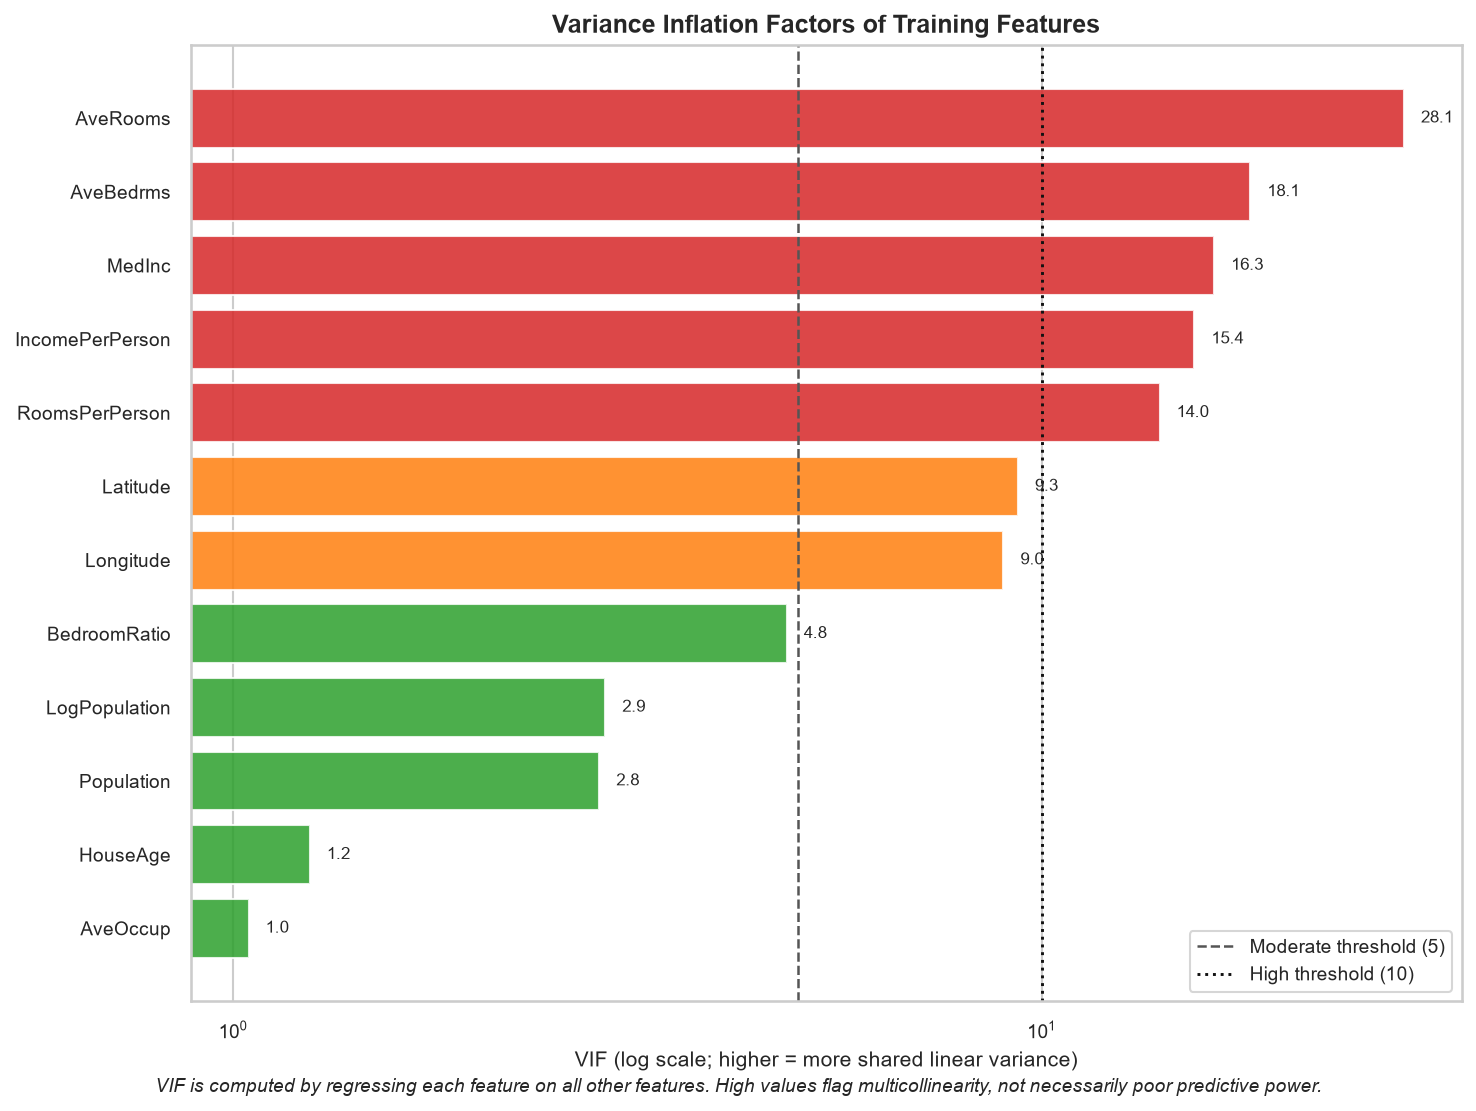

In [14]:
vif_table = variance_inflation_factors(prepared.X_train)
vif_table.to_csv(REPORT_DIR / "vif_analysis.csv", index=False)
vif_path = save_figure(
    plot_vif_analysis(vif_table), FIGURE_DIR / "07_vif_analysis.png"
)
display(vif_table)
show_figure(vif_path)

VIF is computed on **training features only**. Values above 10 flag high shared
linear variance: `AveRooms`, `AveBedrms`, `MedInc`, `IncomePerPerson`, and
`RoomsPerPerson`. `Latitude` and `Longitude` are moderate (about 9). This is
expected because the engineered ratios reuse raw variables and location coordinates
are correlated.

High VIF does not mean a feature must be deleted: it means individual OLS
coefficients are unstable and hard to interpret. Ridge shrinks correlated
coefficients toward zero; Lasso can shrink some to exactly zero. Cross-validation
selects the penalty using training data only.

## 9. Baseline OLS linear regression

In [15]:
ols_result = fit_ols(prepared, n_jobs=1)
ols_train_predictions = ols_result.pipeline.predict(prepared.X_train)
ols_train_rmse = float(
    np.sqrt(np.mean((prepared.y_train - ols_train_predictions) ** 2))
)

print(f"OLS CV RMSE: {ols_result.cv_rmse:.4f} ± {ols_result.cv_std:.4f}")
print(f"OLS training RMSE: {ols_train_rmse:.4f}")
print("OLS test set was not used in this cell.")

OLS CV RMSE: 0.6550 ± 0.0154
OLS training RMSE: 0.6532
OLS test set was not used in this cell.


## 10. Ridge regression and GridSearchCV

In [16]:
ridge_result = tune_regularized_model(prepared, "Ridge", n_jobs=1)
print(f"Selected Ridge alpha: {ridge_result.best_alpha:g}")
print(f"Ridge best CV RMSE: {ridge_result.cv_rmse:.4f} ± {ridge_result.cv_std:.4f}")
print(f"Convergence warnings: {ridge_result.convergence_warnings or 'none'}")

Selected Ridge alpha: 1
Ridge best CV RMSE: 0.6550 ± 0.0154
Convergence warnings: none


Ridge searches `alpha ∈ {0.01, 0.1, 1, 10, 100}` with shuffled five-fold CV and
negative RMSE scoring. The selected alpha is chosen on the training folds; the test
set is not involved.

## 11. Lasso regression and GridSearchCV

In [17]:
lasso_result = tune_regularized_model(prepared, "Lasso", n_jobs=1)
lasso_coefficients = lasso_result.pipeline.named_steps["model"].coef_
lasso_zero_count = int(np.isclose(lasso_coefficients, 0.0, atol=1e-12).sum())

print(f"Selected Lasso alpha: {lasso_result.best_alpha:g}")
print(f"Lasso best CV RMSE: {lasso_result.cv_rmse:.4f} ± {lasso_result.cv_std:.4f}")
print(f"Lasso max_iter: {lasso_result.pipeline.named_steps['model'].max_iter}")
print(f"Exact zero coefficients at selected alpha: {lasso_zero_count}")
print(f"Convergence warnings: {lasso_result.convergence_warnings or 'none'}")

Selected Lasso alpha: 0.001
Lasso best CV RMSE: 0.6548 ± 0.0156
Lasso max_iter: 100000
Exact zero coefficients at selected alpha: 0
Convergence warnings: none


Lasso searches `alpha ∈ {0.001, 0.01, 0.1, 1, 10}` with `max_iter=100000`. The
selected penalty is very weak, so it does **not** zero out coefficients in this run;
the sparsity benefit of L1 is available but not triggered by the CV-optimal alpha.

## 12. Model comparison

In [18]:
results = {
    "OLS": ols_result,
    "Ridge": ridge_result,
    "Lasso": lasso_result,
}
evaluation = evaluate_results(results, prepared.X_test, prepared.y_test)

display(Markdown("### Required comparison table"))
display(Markdown(evaluation.metrics_markdown()))
display(
    evaluation.metrics[
        ["Model", "Test RMSE (USD)", "Test MAE (USD)", "Test Samples"]
    ].round(2)
)

report_paths = write_evaluation_reports(
    evaluation, REPORT_DIR, cv_folds=5, random_state=RANDOM_STATE
)
model_paths = save_models(results, MODEL_DIR)
print("Reports written:")
for name, path in report_paths.items():
    print(f"  {name}: {path.relative_to(PROJECT_ROOT)}")
print("Models written:")
for name, path in model_paths.items():
    print(f"  {name}: {path.relative_to(PROJECT_ROOT)}")

### Required comparison table

| Model | Best Alpha | CV RMSE | Test RMSE | Test MAE | Test R² |
| --- | --- | ---: | ---: | ---: | ---: |
| OLS | N/A | 0.6550 | 0.6621 | 0.4737 | 0.6655 |
| Ridge | 1 | 0.6550 | 0.6621 | 0.4737 | 0.6655 |
| Lasso | 0.001 | 0.6548 | 0.6626 | 0.4741 | 0.6649 |

,Model,Test RMSE (USD),Test MAE (USD),Test Samples
0,OLS,66210.09,47374.01,4128
1,Ridge,66210.62,47373.98,4128
2,Lasso,66264.53,47411.03,4128


Reports written:
  metrics_csv: outputs\reports\model_comparison.csv
  comparison_markdown: outputs\reports\model_comparison.md
  residual_csv: outputs\reports\residual_summary.csv
  coefficient_csv: outputs\reports\coefficient_analysis.csv
Models written:
  OLS: models\ols_pipeline.joblib
  Ridge: models\ridge_pipeline.joblib
  Lasso: models\lasso_pipeline.joblib


The three models are effectively tied. OLS has the lowest observed test RMSE by a
tiny margin, Ridge's CV-optimal penalty is essentially neutral, and Lasso's test
performance is slightly worse. The CV RMSE differences are much smaller than the
fold-to-fold variation. This is evidence that **regularization does not materially
improve accuracy here**; the dominant limitation is the linear model's functional
form. Hyperparameters were still selected only on training data.

actual_vs_predicted: outputs\figures\08_actual_vs_predicted.png
residuals_vs_predicted: outputs\figures\09_residuals_vs_predicted.png
residual_distributions: outputs\figures\10_residual_distributions.png
metric_comparison: outputs\figures\11_metric_comparison.png
coefficient_comparison: outputs\figures\12_coefficient_comparison.png


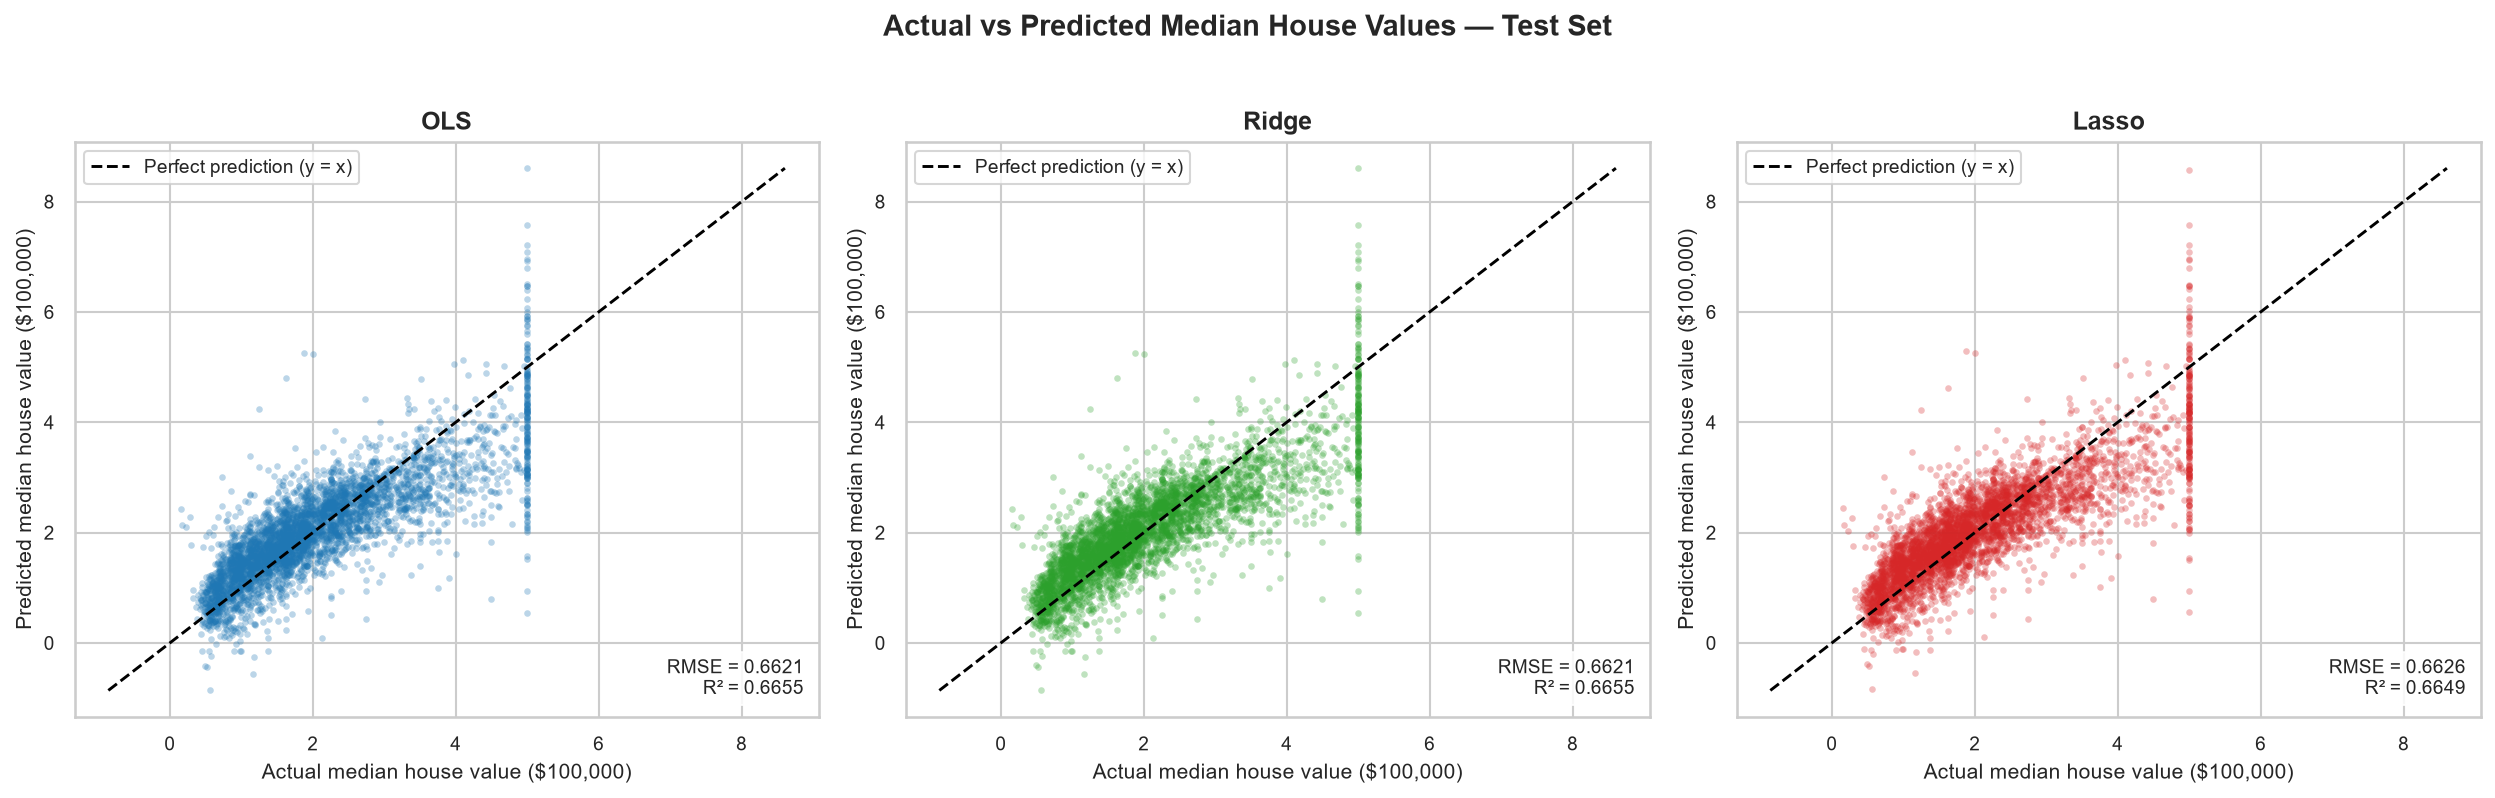

In [19]:
diagnostic_paths = generate_diagnostic_figures(evaluation, FIGURE_DIR)
for name, path in diagnostic_paths.items():
    print(f"{name}: {path.relative_to(PROJECT_ROOT)}")

show_figure(diagnostic_paths["actual_vs_predicted"])

Actual-versus-predicted points should lie on the dashed `y = x` line for perfect
predictions. The cloud is compressed toward the middle and the high-value region is
under-predicted, which is consistent with the capped target and the limited
flexibility of a linear model.

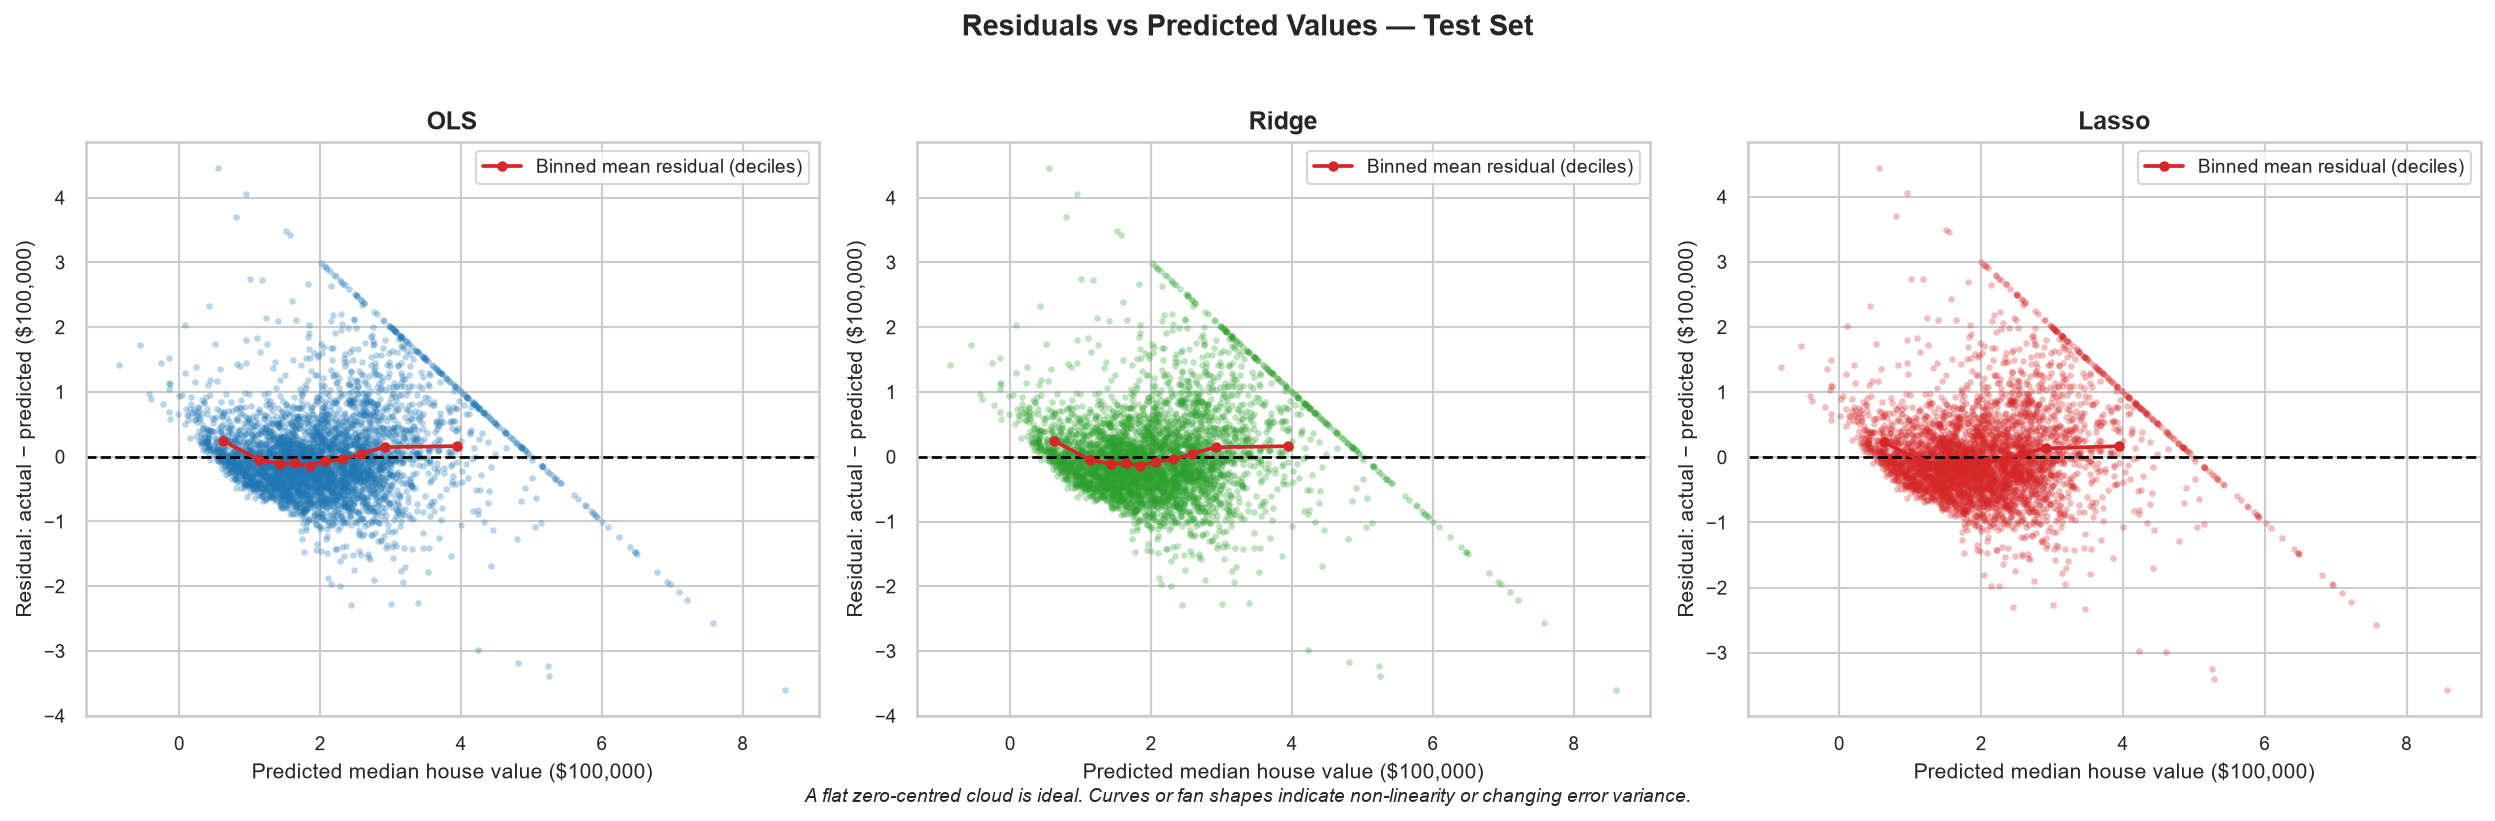

In [20]:
show_figure(diagnostic_paths["residuals_vs_predicted"])

Residuals are `actual − predicted`. The red curve is the mean residual by predicted
decile. A flat curve at zero would be ideal; the visible U-shape indicates
non-linearity: low predictions are too low, middle predictions are slightly too
high, and high predictions are too low. The spread also changes across the
prediction range, so the errors are not homoscedastic.

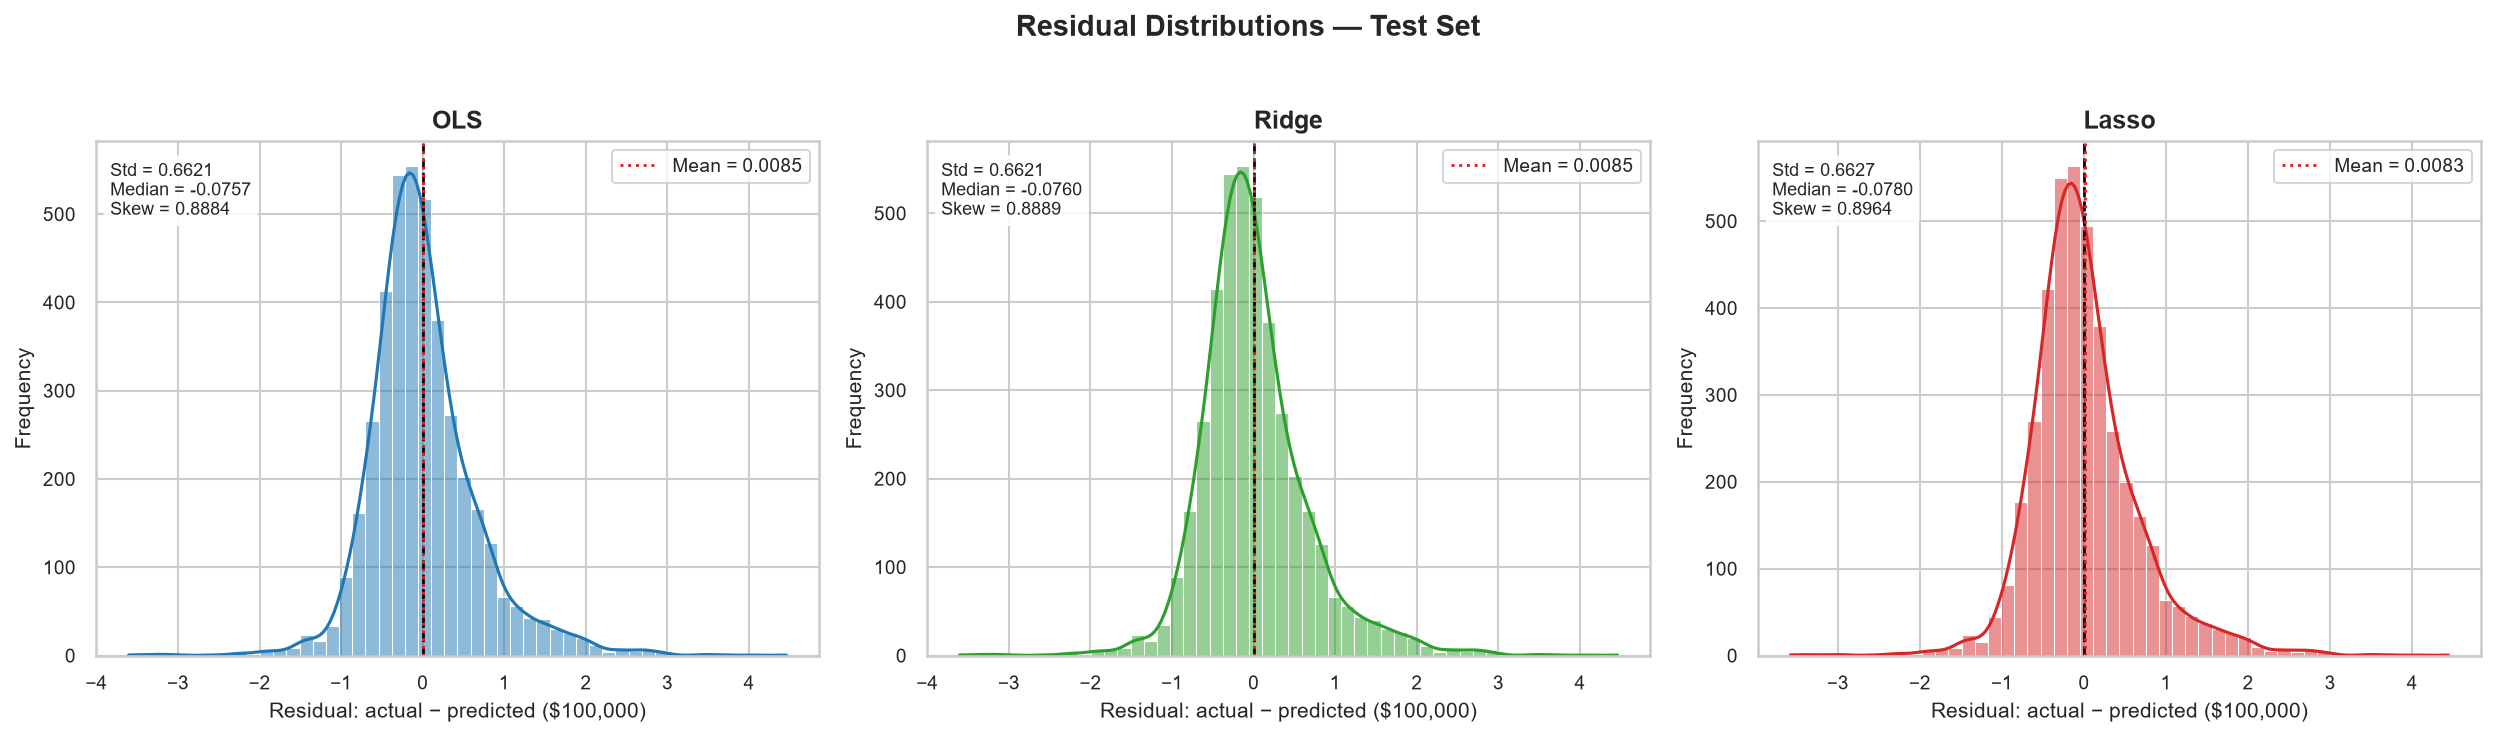

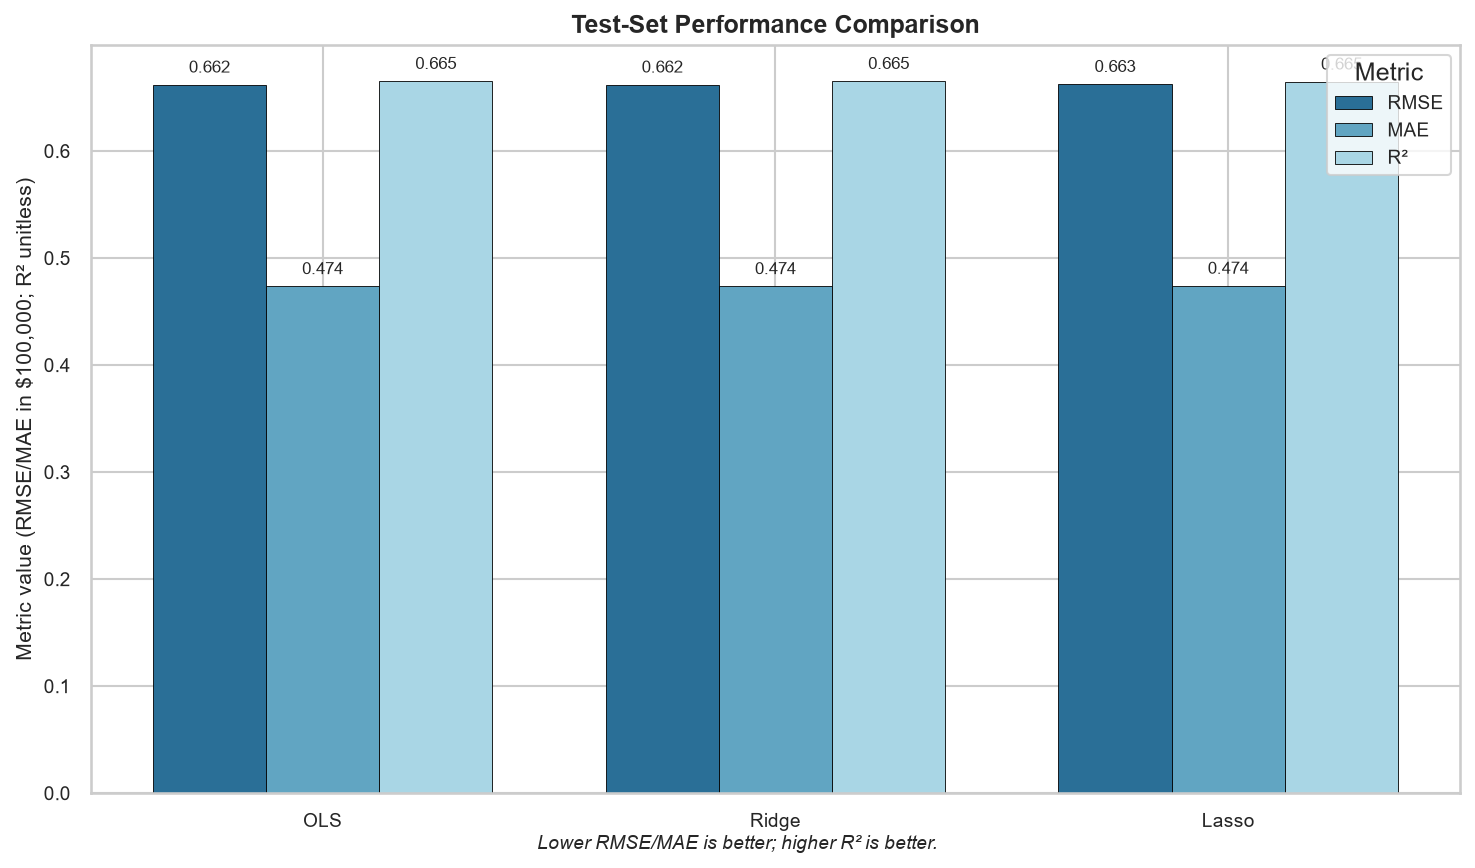

In [21]:
show_figure(diagnostic_paths["residual_distributions"])
show_figure(diagnostic_paths["metric_comparison"])

Residual distributions are right-skewed: there are large positive residuals where
expensive homes are under-predicted, plus a smaller tail of over-predictions. The
bar chart compares RMSE, MAE, and R² on the same test split; lower RMSE/MAE and
higher R² are better.

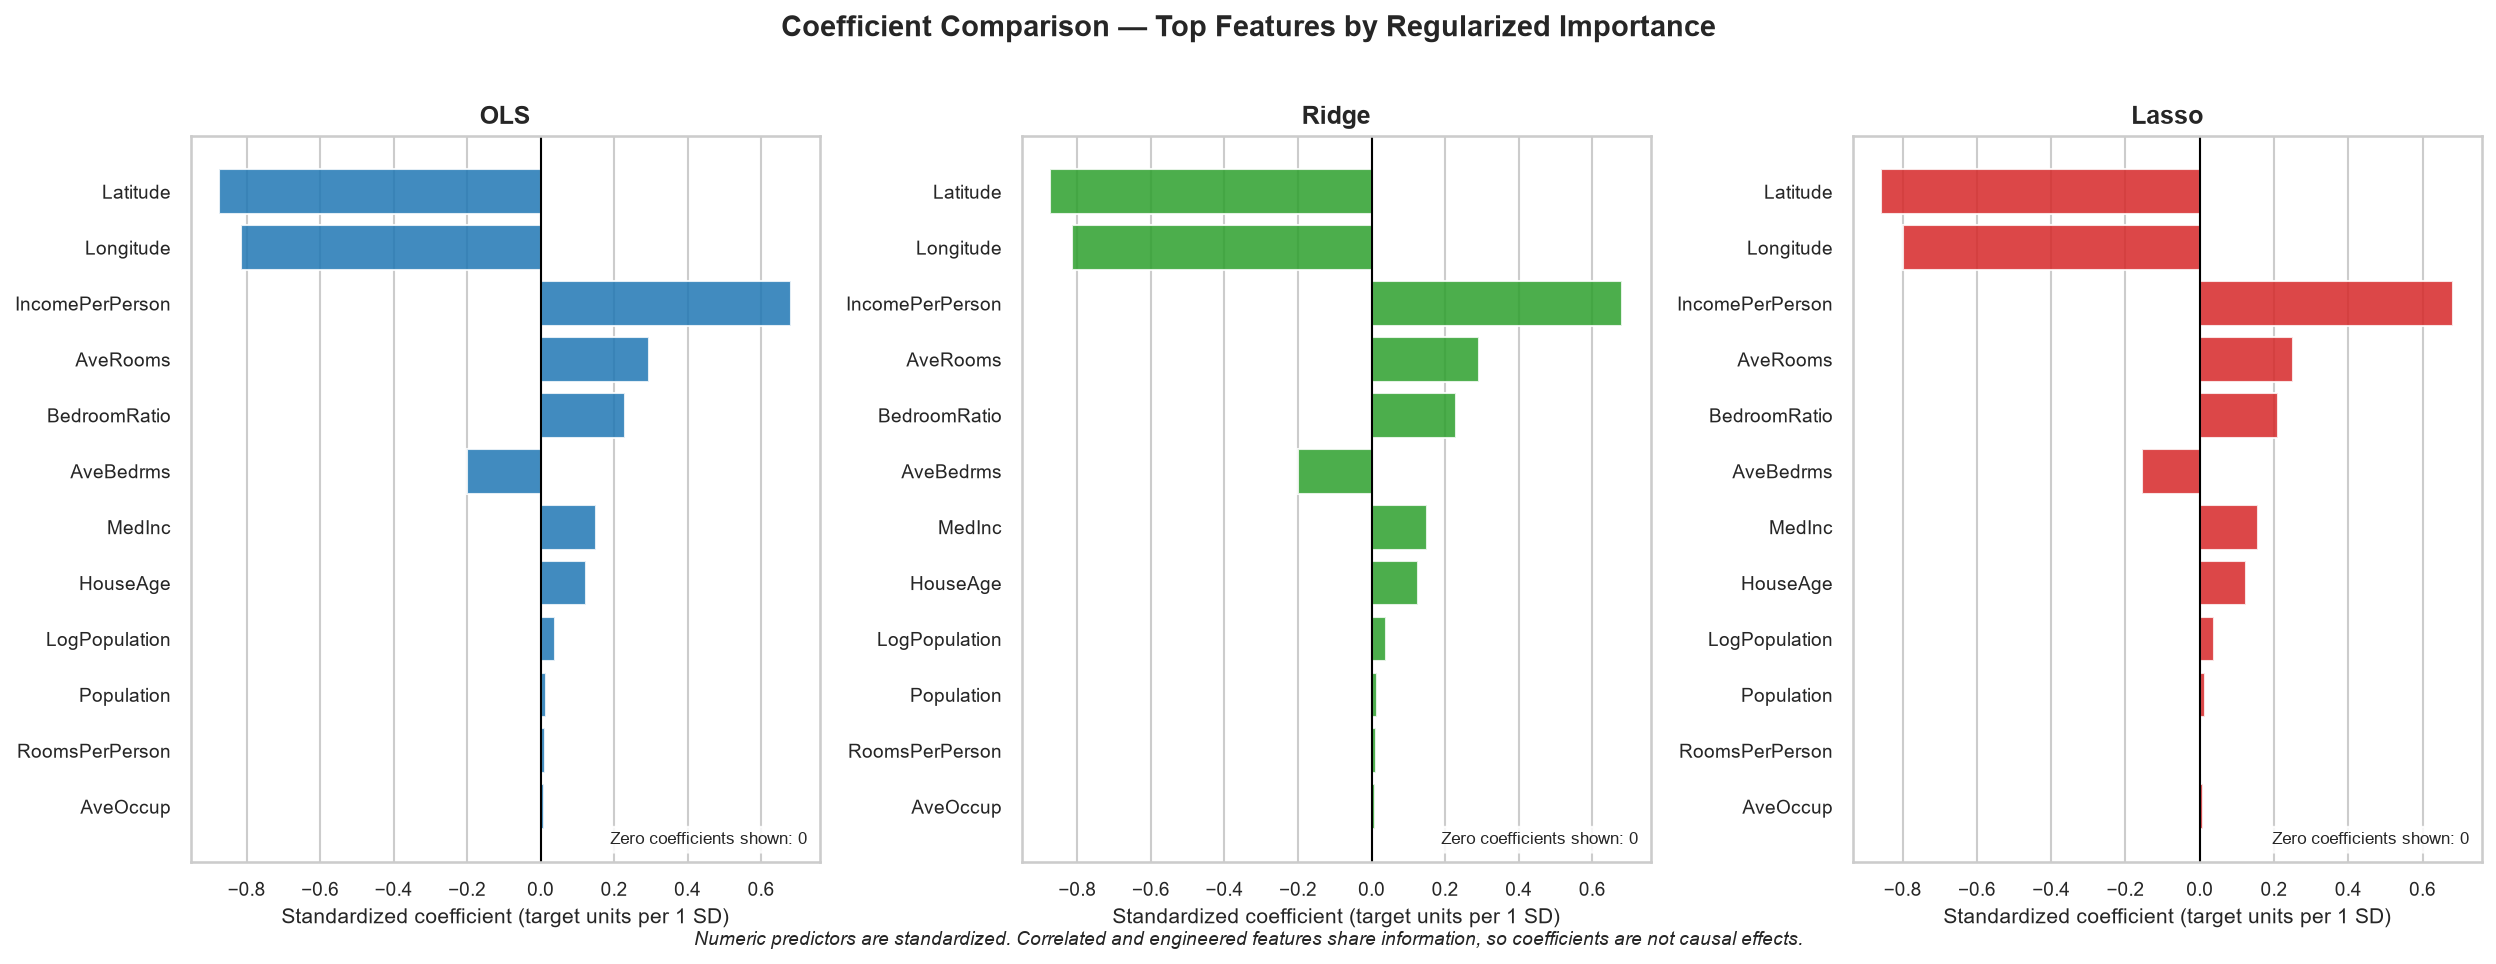

In [22]:
show_figure(diagnostic_paths["coefficient_comparison"])

Coefficient comparison for the 12 largest regularized features. Numeric features are
standardized, so coefficients are in target units per one-standard-deviation change.
Ridge shrinks the OLS coefficients only slightly; Lasso's selected alpha is weak and
leaves no exact zeros. Latitude and longitude have large coefficients but are
strongly correlated with each other, and engineered ratios share components with raw
features. These are conditional associations, **not causal effects**.

## 13. Sample prediction in target units and dollars

In [23]:
sample_index = prepared.X_test.index[0]
sample_raw = {
    column: float(prepared.X_test.loc[sample_index, column])
    for column in FEATURE_COLUMNS
}
sample_actual = float(prepared.y_test.loc[sample_index])

sample_rows = []
for name, result in results.items():
    predicted_100k = predict_house_value(result.pipeline, sample_raw)
    sample_rows.append(
        {
            "Model": name,
            "Predicted (100k)": predicted_100k,
            "Predicted (USD)": predict_house_value_dollars(
                result.pipeline, sample_raw
            ),
            "Actual (100k)": sample_actual,
            "Absolute Error (USD)": abs(sample_actual - predicted_100k) * 100_000,
        }
    )
display(pd.DataFrame(sample_rows).round(2))
print("Raw input features:")
display(pd.Series(sample_raw, name="value").to_frame())

,Model,Predicted (100k),Predicted (USD),Actual (100k),Absolute Error (USD)
0,OLS,0.59,58592.32,0.48,10892.32
1,Ridge,0.59,58619.10,0.48,10919.10
2,Lasso,0.59,59443.68,0.48,11743.68


Raw input features:


,value
MedInc,1.681200
HouseAge,25.000000
AveRooms,4.192201
AveBedrms,1.022284
Population,1392.000000
AveOccup,3.877437
Latitude,36.060000
Longitude,-119.010000


The helper accepts the eight raw inputs, adds the engineered features internally,
and returns the prediction in the documented target units. The USD value is simply
the target-unit prediction multiplied by 100,000.

## 14. Residual analysis in detail

In [24]:
display(evaluation.residual_summary.round(4))

ols_predictions = evaluation.predictions["OLS"]
ols_residuals = evaluation.residuals["OLS"]
residual_frame = pd.DataFrame(
    {"predicted": ols_predictions, "residual": ols_residuals}
)
residual_frame["prediction_decile"] = pd.qcut(
    residual_frame["predicted"], q=10, duplicates="drop"
)
binned_residuals = (
    residual_frame.groupby("prediction_decile", observed=True)
    .agg(
        mean_predicted=("predicted", "mean"),
        mean_residual=("residual", "mean"),
        count=("residual", "size"),
    )
    .reset_index(drop=True)
)
display(binned_residuals.round(4))

absolute_residuals = np.abs(ols_residuals)
print(f"Share within 0.5 target units (~$50k): {np.mean(absolute_residuals <= 0.5):.2%}")
print(f"Share within 1.0 target units (~$100k): {np.mean(absolute_residuals <= 1.0):.2%}")
print(f"Largest absolute OLS error: {absolute_residuals.max():.4f} target units (~${absolute_residuals.max() * 100_000:,.0f})")

,Model,Mean Residual,Median Residual,Residual Std,Min Residual,Q25 Residual,Q75 Residual,Max Residual,Max Abs Residual,Test MAE,Test RMSE,"Corr(Prediction, Residual)"
0,OLS,0.0085,-0.0757,0.6621,-3.6057,-0.3810,0.3000,4.4573,4.4573,0.4737,0.6621,-0.0197
1,Ridge,0.0085,-0.0760,0.6621,-3.6045,-0.3809,0.3001,4.4581,4.4581,0.4737,0.6621,-0.0195
2,Lasso,0.0083,-0.0780,0.6627,-3.5760,-0.3816,0.2985,4.4413,4.4413,0.4741,0.6626,-0.0152


,mean_predicted,mean_residual,count
0,0.6195,0.2476,413
1,1.1300,-0.0516,413
2,1.4281,-0.1076,413
3,1.6386,-0.1040,412
4,1.8473,-0.1392,413
5,2.0646,-0.0733,413
6,2.3109,-0.0409,412
7,2.5727,0.0437,413
8,2.9126,0.1474,413
9,3.9402,0.1628,413


Share within 0.5 target units (~$50k): 65.41%
Share within 1.0 target units (~$100k): 90.26%
Largest absolute OLS error: 4.4573 target units (~$445,733)


The mean residual is close to zero, but that does **not** make the model unbiased:
the median residual is negative, the error range is wide, and the binned means
follow a U-shape. The largest errors correspond to roughly $445k on the target
scale. The model compresses predictions toward the middle and under-predicts the
expensive, capped part of the distribution. Residual variance changes with the
prediction level, so standard constant-variance assumptions would be inappropriate.

## 15. Coefficient interpretation and limitations

In [25]:
coefficient_pivot = evaluation.coefficients.pivot(
    index="Feature", columns="Model", values="Coefficient"
)
top_features = (
    coefficient_pivot.abs().max(axis=1).sort_values(ascending=False).head(10).index
)
display(coefficient_pivot.loc[top_features].round(3))

zero_counts = (
    evaluation.coefficients.assign(
        is_zero=np.isclose(evaluation.coefficients["Coefficient"], 0.0, atol=1e-12)
    )
    .groupby("Model")["is_zero"]
    .sum()
    .rename("zero_coefficients")
)
display(zero_counts.to_frame())

Model,Lasso,OLS,Ridge
Feature,,,
Latitude,-0.857,-0.874,-0.873
Longitude,-0.798,-0.814,-0.814
IncomePerPerson,0.682,0.681,0.681
AveRooms,0.251,0.295,0.293
BedroomRatio,0.210,0.229,0.228
AveBedrms,-0.156,-0.199,-0.199
MedInc,0.158,0.150,0.151
HouseAge,0.125,0.125,0.125
LogPopulation,0.039,0.039,0.039


,zero_coefficients
Model,
Lasso,0
OLS,0
Ridge,0


**How to read the coefficients**

- Numeric inputs were standardized, so coefficients are comparable within a model
  on a per-standard-deviation basis.
- A positive coefficient means the prediction increases when that standardized
  feature increases, holding the other included features fixed.
- Latitude and longitude are strongly correlated; their individual signs and
  magnitudes are unstable and should not be interpreted as independent geographic
  effects.
- Engineered ratios share inputs with raw features, so coefficient attribution is
  ambiguous.
- One-hot encoded categories, when present, are relative to a reference level.
- Coefficients describe associations in this linear specification; they do **not**
  establish causality.

**Feature importance limitation:** coefficient magnitude is not a reliable universal
importance measure under collinearity, differing feature scales (handled here by
scaling), or non-linear effects. Permutation importance or SHAP on a non-linear
model would answer a different question and is left for future work.

## 16. Final findings and limitations

In [26]:
best_test = evaluation.metrics.sort_values("Test RMSE").iloc[0]
best_cv = min(results.values(), key=lambda result: result.cv_rmse)
print(
    f"Lowest observed test RMSE: {best_test['Model']} "
    f"({best_test['Test RMSE']:.4f} target units, ~${best_test['Test RMSE'] * 100_000:,.0f})"
)
print(
    f"Best CV RMSE: {best_cv.name} "
    f"({best_cv.cv_rmse:.4f} ± {best_cv.cv_std:.4f})"
)
print(
    f"Test R² range: {evaluation.metrics['Test R²'].min():.4f} "
    f"to {evaluation.metrics['Test R²'].max():.4f}"
)

Lowest observed test RMSE: OLS (0.6621 target units, ~$66,210)
Best CV RMSE: Lasso (0.6548 ± 0.0156)
Test R² range: 0.6649 to 0.6655


### Findings

1. **The dataset is clean but censored.** There are no missing values or duplicate
   rows, but 965 target values (4.68%) are capped near $500,001.
2. **Income and location dominate.** `MedInc` has the strongest marginal correlation
   with price (`r ≈ 0.69`), while coastal geography produces a clear spatial pattern.
3. **Multicollinearity is real.** VIF is high for room-related features and
   `MedInc`-derived ratios, and latitude/longitude correlate at about 0.925.
4. **Regularization did not improve test accuracy materially.** OLS, Ridge, and
   Lasso are tied within a few hundred dollars of RMSE. The selected Lasso penalty
   is too weak to zero any coefficients in this run.
5. **The errors show structure.** Residuals are right-skewed, heteroscedastic, and
   U-shaped across predictions. The linear specification compresses the extremes and
   under-predicts the most expensive block groups.
6. **Predictions are useful but uncertain.** About 65% of test errors are within
   $50,000, but the largest errors exceed $400,000.

### Limitations

- Block-group aggregates are not individual houses, so within-group variation is
  invisible.
- Target censoring at the cap prevents accurate prediction above about $500k.
- Linear models cannot represent complex interactions or spatial non-stationarity
  without explicit feature engineering.
- One random split is used; repeated or spatial cross-validation would give a more
  stable performance estimate.
- Residual diagnostics indicate non-constant variance and non-linearity, so
  classical OLS inference is not appropriate.

### Future improvements

- Spatial features (distance to coast/city centres, neighbourhood aggregates) and
  spatial cross-validation.
- Gradient boosting or random forests to capture non-linearities and interactions.
- Quantile regression or prediction intervals to communicate uncertainty.
- Robust regression for the heavy tails and a two-stage model for the capped values.
- Repeated nested cross-validation for a more reliable model comparison.